# TP1 : Génération de variables aléatoires

## G3 SDI - Estimation Avancée

Dans ce TP, on s'intéresse à la génération de variables aléatoires, i.e., la capacité de produire des échantillons finis de variables ou vecteurs aléatoires d'une loi donnée.
* Dans un premier temps, on suppose que l'on dispose d'un générateur de loi uniforme sur $[0,1]$ (avec Numpy, il est donné par `np.random.rand`). À partir de ce générateur, le but sera de générer des échantillons d'autres lois avec des méthodes simples, notamment la méthode de la transformée inverse.
* Dans un deuxième temps, on étudiera des méthodes plus sophistiquées (acceptation-rejet, échantillonnage d'importance).

Pour chaque question, **justifier brièvement la solution puis l'implémenter**. **Comparer avec la densité théorique** à l'aide d'histogrammes ou de KDE.

### Instructions

1. Renommez votre notebook sous la forme `tp1_Nom1_Nom2.ipynb`. 

2. Votre code, ainsi que toute sortie du code, doivent être commentés !

3. Déposez votre notebook sur Moodle dans la section prévue à cet effet avant la date limite.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Compte-rendu écrit par FERNANDES--STRAG Henry, TORRES--Leguet Alexandre, 25/11/26.
</div>

In [20]:
# Importing usual libraries
import numpy as np
from matplotlib import pyplot as plt
from sklearn.neighbors import KernelDensity

### Exercice 1 - Pour commencer : lois uniformes

**Q1**. À partir de $N$ échantillons d'une loi uniforme sur l'intervalle $[0,1]$, comment obtenir $N$ échantillons d'une loi uniforme sur l'intervalle $[a,b]$ ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Soit $u \in [0, 1]$, alors :

$$ 0 \leq u \leq 1$$

et donc :

$$ 0 \leq u (b-a) \leq b-a $$

puis :

$$ a \leq u (b-a) + a \leq b $$

ie, on applique des transformations pour passer de l'intervalle $[0,1]$ à $[a,b]$.

On prend alors $U \sim U([0,1])$, et on calcule $X = U(b-a) + a$, qui suit $U([a,b])$

En effet, pour $t \in [a,b]$ :

$$ P(X \leq t) = P\Big(U \leq \frac{t-a}{b-a}\Big) = \frac{t-a}{b-a} $$

qui est bien la fonction de répartition de la loi $U([a,b])$.

Expérimentalement, on a bien la densité de la loi uniforme sur $[a,b]$ :
</div>

In [21]:
np.random.seed(0)

N = 10000
a, b = 7, 10

U = np.random.uniform(low=0, high=1, size=N)
X = U * (b - a) + a

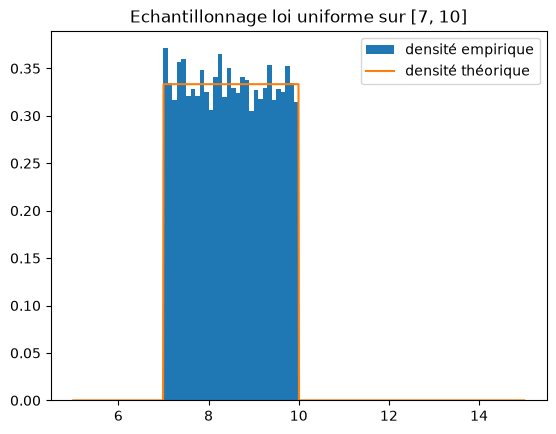

In [22]:
from scipy.stats import uniform

# comparaison densité empirique / densité théorique de U([a, b])

x = np.linspace(5, 15, 1000)

plt.hist(X, bins=30, density=True, label="densité empirique")
plt.plot(x, uniform.pdf(x, loc=a, scale=b-a), label="densité théorique")
plt.title(f"Echantillonnage loi uniforme sur [{a}, {b}]")
plt.legend()
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

L'histogramme fluctue bien autour de 1/(b-a) sur [a,b], ce qui correspond à la densité théorique.

</div>

**Q2**. Comment obtenir $N$ échantillons d'une loi uniforme sur le pavé $[a,b] \times [c,d]$ ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On génère $N$ couples $U = (U_1, U_2)$ avec $U_1, U_2$ indépendantes de loi uniforme sur $[0,1]$, puis on applique la transformation de Q1 à chaque composante :
$$
V = (V_1, V_2) = \big(a + (b-a)\,U_1,\; c + (d-c)\,U_2\big).
$$

D'après la Q1, $V_1 \sim \mathcal{U}([a,b])$ et $V_2 \sim \mathcal{U}([c,d])$. De plus elles restent indépendantes par fonctions de variables indépendantes. La densité de $V$ est donc le produit des densités marginales :
$$
f_V(x,y) = \frac{1}{(b-a)(d-c)}\,\mathbb{1}_{[a,b]}(x)\,\mathbb{1}_{[c,d]}(y),
$$
c'est-à-dire la densité de la loi uniforme sur le pavé $[a,b] \times [c,d]$.

</div>

In [23]:
np.random.seed(0)

N = 1000
a, b, c, d = 7, 10, 3, 4

U = np.random.uniform(low=0, high=1, size=(N, 2))
X = U * np.array([b - a, d - c]) + np.array([a, c]) # broadcasting : (N, 2) * (2,) + (2,) = (N, 2)

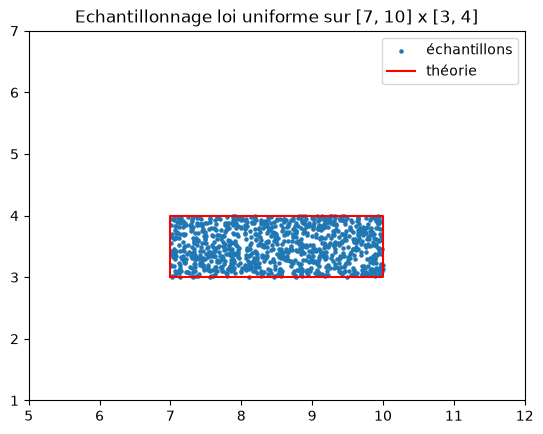

In [24]:
# comparaison densité empirique / densité théorique

plt.scatter(X[:, 0], X[:, 1], s=5, label="échantillons")
plt.plot([a, b, b, a, a], [c, c, d, d, c], color='red', label="théorie")
plt.xlim(5, 12)
plt.ylim(1, 7)
plt.title(f"Echantillonnage loi uniforme sur [{a}, {b}] x [{c}, {d}]")
plt.legend()
plt.show()

**Q3**. À partir de $N$ échantillons de loi uniforme sur l'intervalle $[0,1]$, comment obtenir $N$ échantillons de loi uniforme discrète sur $\{1, ..., K\}$ ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On divise l'intervalle $[0,1]$ en $K$ sous-intervalles de même taille : $[a_k, a_{k+1}[$ avec $k=0,...,K$ et $a_k = \frac{k}{K}$. Sur chacun des intervalles, on assigne une valeur discrète entre $1$ et $K$. Donc en fonction de là où tombe la valeur dans $[0,1]$, on en déduit une valeur discrète. Plus formellement :

Soit $U \sim U([0,1])$. On pose alors :

$$X = \sum_{k=0}^{K-1} 1_{[\frac{k}{K}, \frac{k+1}{K}[}(U) . (k+1)$$

Alors $X$ suit la loi uniforme discrète sur ${1, ..., K}$.
En effet, soit $k \in \{1...K\}$, alors :

$$ P(X=k) = P(U \in [\frac{k-1}{K}, \frac{k}{K}]) = \frac{1}{K}$$

Remarque : on a aussi:

$$
X = \lfloor K\,U \rfloor + 1 .
$$

En effet, pour $k \in \{1, \dots, K\}$,
$$
X = k \iff k-1 \le K U < k \iff U \in \Big[\tfrac{k-1}{K}, \tfrac{k}{K}\Big[
$$


On vérifie cela expérimentalement :
</div>

In [25]:
np.random.seed(0)

N = 10000
K = 7

U = np.random.uniform(low=0, high=1, size=N)

# version 1 avec la première définition qui utilise les tests sur tous les intervalles
#X = np.zeros(N)
#for k in range(0, K):
#    # positions entre [1,N] pour lesquelles U est compris entre k/K et (k+1)/K -> valeur k+1
#    X[(U >= k/K) & (U < (k+1)/K)] = k + 1

# version 2 avec la seconde def, via floor
X = np.floor(K * U).astype(int) + 1

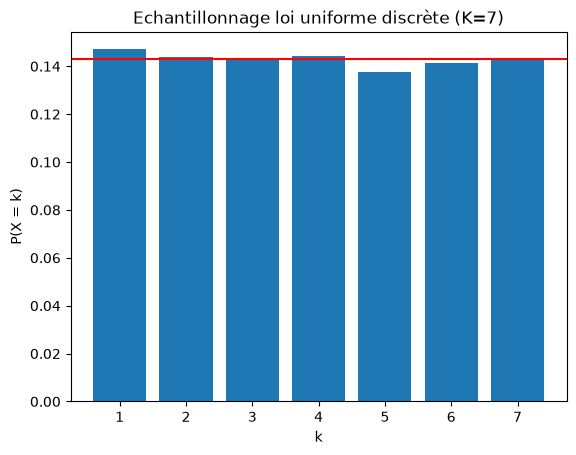

In [26]:
# comparaison distribution empirique / loi théorique uniforme

plt.hist(X, bins=np.arange(0.5, K + 1.5, 1), density=True, rwidth=0.8,)
plt.axhline(y=1/K, color='red')
plt.xticks(range(1, K + 1))
plt.xlabel("k")
plt.ylabel("P(X = k)")
plt.title(f"Echantillonnage loi uniforme discrète (K={K})")
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On observe bien la distribution d'une valeur aléatoire discrète uniforme à valeur dans $\{ 1, ..., K\}$ avec ici $K=7$, avec $P(X=k) = \frac{1}{K} = \frac{1}{7} \approx 0.14$.

</div>

### Exercice 2 - Méthode de la transformée inverse

Soit $X$ une variable aléatoire réelle de fonction de répartition $F$ (rappel : $F$ est une fonction croissante de $\mathbb{R}$ dans $[0,1]$, et "càdlàg", mais pas nécessairement bijective). On définit la **fonction inverse généralisée** $F^{-1}$ de $F$ par :
$$\forall~u \in [0,1],~F^{-1}(u) = \inf\{x \in \mathbb{R}, F(x) \geq u\}.$$

Cette fonction conïncide avec l'inverse classique quand $F$ est bijective (attention même si $F$ est continue elle n'est pas nécessairement bijective, il peut y avoir des plateaux). On a la proposition suivante :

<div style="background-color: rgba(255, 0, 0, 0.15); padding: 8px;">

Si $U$ suit la loi uniforme sur l'intervalle $[0,1]$, alors la v.a. $F^{-1}(U)$ a pour fonction de répartition $F$ (et donc la même loi que $X$).

</div>

Cela donne donc la méthode de la **transformée inverse** ; Si l'on connait explicitement la fonction $F^{-1}$, on peut simuler de n'importe quelle variable aléatoire réelle à partir d'un échantillon de loi uniforme.

**Q1**. À l'aide de cette méthode, simuler $N$ échantillons d'une loi exponentielle de paramètre $\lambda$.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Soit $X \sim \text{Exp}(\lambda)$, ie de densité $x \rightarrow \lambda \text{exp}(-\lambda x) 1_{\R_+} (x)$.

On calcule la fonction de répartition $F_X$. Soit $t \in \R$.

$$
F_X(t) = P(X \leq t) = \int_0^t \lambda \text{exp}(-\lambda x) dx = 1 - \text{exp}(-\lambda t)
$$

La fonction $t \rightarrow 1 - \text{exp}(-\lambda t)$ est bien bijective de $\R_+$ sur $[0,1[$.
On cherche alors sa fonction réciproque, c'est-à-dire, on résoud l'équation :

$$ F_X(t) = u$$

ie:

$$1-\text{exp}(-\lambda t) = u$$

donc:

$$\text{ln}(1-u) = -\lambda t$$

et donc :

$$F^{(-1)}(u) = -\frac{\text{ln}(1-u)}{\lambda}$$

sur $\R_+$. ($F$ vaut $0$ sur $\R_-$)

Ainsi, si $U \sim U([0,1])$, alors $-\frac{\text{ln}(1-U)}{\lambda} \sim \text{Exp}(\lambda)$.

On teste cela dans le code suivant, et l'on compare l'histogramme expérimental avec l'histogramme théorique.

</div>

In [27]:
np.random.seed(0)

N = 10000
lambd = 2

U = np.random.uniform(low=0, high=1, size=N)
X = -np.log(1-U)/lambd

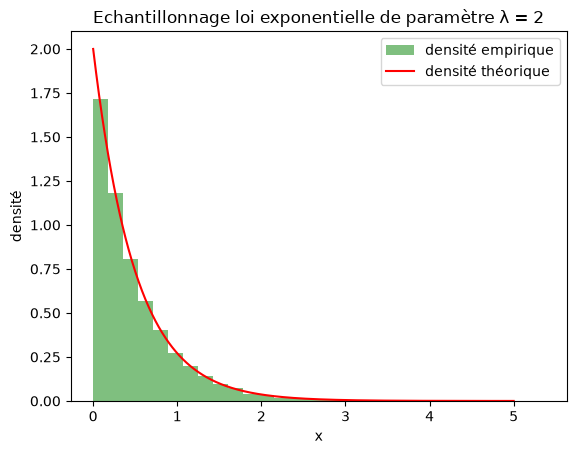

In [28]:
# comparaison densité empirique / densité théorique de Exp(lambda)
plt.hist(X, bins=30, density=True, alpha=0.5, color='g', label="densité empirique")
x = np.linspace(0, 5, 1000)
plt.plot(x, lambd * np.exp(-lambd * x), color='red', label="densité théorique")
plt.xlabel("x")
plt.ylabel("densité")
plt.title(f"Echantillonnage loi exponentielle de paramètre λ = {lambd}")
plt.legend()
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

La distribution empirique des échantillons correspond bien à la distribution théorique.
On arrive donc bien à échantillonner la loi $\text{Exp}$, grâce à une loi uniforme.

</div>

**Q2**. Quelles sont d'après vous les limitations de la méthode de la transformée inverse ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

La méthode de la transformée inverse est limitante car elle nécessite à la fois de connaître une formule explicite de la fonction de répartition, ainsi que de calculer son inverse généralisé qui n'admet pas toujours de forme explicite. Il faut donc passer par des méthodes numériques pour d'abord calculer $F^{-1}$ pour ensuite appliquer cette méthode.
De plus, appliquer cette méthode au cas multivarié non indépendant semble délicat car on ne peut pas décomposer simplement la fonction de répartition selon les composantes.

</div>

### Exercice 3 - Méthode de Box-Müller

On a la proposition suivante :

<div style="background-color: rgba(255, 0, 0, 0.15); padding: 8px;">

Soit $R \sim \text{Exp}(1/2)$ et $\Theta \sim U([0, 2 \pi])$ deux variables aléatoires indépendantes.
    
Alors $X = \sqrt{R} \cos(\Theta)$ et $Y = \sqrt{R} \sin(\Theta)$ sont deux variables indépendantes de loi $\mathcal{N}(0,1)$.

</div>

Cette méthode est connue comme la méthode de **Box-Müller** (1958), et est l'une des méthodes de référence pour générer des variables aléatoires normales.

**Q1 (Bonus)**. Montrer la proposition.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Comme $R$ et $\Theta$ sont indépendantes, la densité du couple $(R, \Theta)$ est le produit des densités :

$$ f_{R,\Theta}(r, \theta) = \frac{1}{2} e^{-r/2} \mathbb{1}_{]0, +\infty[}(r) \times \frac{1}{2\pi} \mathbb{1}_{]0, 2\pi[}(\theta) $$

On utilise la méthode de la fonction muette. Soit $h : \mathbb{R}^2 \to \mathbb{R}$ une fonction mesurable à support compact. On a :

$$ \mathbb{E}[h(X, Y)] = \mathbb{E}\big[h(\sqrt{R}\cos\Theta, \sqrt{R}\sin\Theta)\big] = \int_0^{2\pi} \int_0^{+\infty} h(\sqrt{r}\cos\theta, \sqrt{r}\sin\theta) \, \frac{1}{2} e^{-r/2} \, \frac{1}{2\pi} \, dr \, d\theta $$

On considère alors le changement de variable défini par :

$$ \phi : (r, \theta) \mapsto (x, y) = \big(\sqrt{r}\cos\theta, \sqrt{r}\sin\theta\big) $$

C'est un $\mathcal{C}^1$-difféomorphisme de $]0, +\infty[ \times ]0, 2\pi[$ sur $\mathbb{R}^2 \setminus \{y = 0, x \geq 0\}$ (ie, $\mathbb{R}^2$ auquel on a retiré un ensemble de mesure nulle), avec $r = x^2 + y^2$.

On calcule :

$$ \det J_\phi(r, \theta) = \begin{vmatrix} \frac{\cos\theta}{2\sqrt{r}} & -\sqrt{r}\sin\theta \\ \frac{\sin\theta}{2\sqrt{r}} & \sqrt{r}\cos\theta \end{vmatrix} = \frac{\cos^2\theta}{2} + \frac{\sin^2\theta}{2} = \frac{1}{2} $$

Ainsi, par le théorème du changement de variable :

$$ \mathbb{E}[h(X, Y)] = \int_{\mathbb{R}^2} h(x, y) \, \frac{1}{2} e^{-(x^2+y^2)/2} \, \frac{1}{2\pi} \times 2 \, dx \, dy = \int_{\mathbb{R}^2} h(x, y) \, \frac{1}{2\pi} e^{-(x^2+y^2)/2} \, dx \, dy $$

On peut donc identifier la densité de $(X,Y)$ :

$$ f_{X,Y}(x, y) = \frac{1}{2\pi} e^{-(x^2+y^2)/2} $$

On remarque aussi que cette densité se factorise de la manière suivante :

$$ f_{X,Y}(x, y) = \frac{1}{\sqrt{2\pi}} e^{-x^2/2} \times \frac{1}{\sqrt{2\pi}} e^{-y^2/2} $$

Ce qui montre que $X$ et $Y$ sont indépendantes de loi $\mathcal{N}(0,1)$.

</div>

**Q2**. En déduire une façon de générer un $N$ échantillons de loi normale $\mathcal{N}(0,1)$ à partir d'échantillons d'une loi uniforme sur l'intervalle $[0,1]$.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Soit $U,V \sim U([0, 1])$ indépendantes.

On utilise l'exercice 2 pour "transformer" $U$ en une variable aléatoire de loi $\text{Exp}(\frac{1}{2})$ :

$$ R = -2\text{ln}(1-U) \sim \text{Exp}(\frac{1}{2})$$

et l'exercice 1 pour "transformer" $V$ en une variable aléatoire de loi $U([0, 2\pi])$ :

$$ \Theta = V(2\pi - 0) + 0 \sim U([0, 2\pi])$$

Ainsi, on applique alors la Q1 qui nous assure que $X = \sqrt{R} \cos(\Theta)$ et $Y = \sqrt{R} \sin(\Theta)$ sont deux variables indépendantes de loi $\mathcal{N}(0,1)$

Vérification empirique :
</div>

In [29]:
np.random.seed(0)

N = 10000

U = np.random.uniform(low=0, high=1, size=N)
V = np.random.uniform(low=0, high=1, size=N)

R = -2*np.log(1-U) # suit exp(1/2)
Theta = 2*np.pi*V # suit U(0, 2pi)

X = np.sqrt(R) * np.cos(Theta)
Y = np.sqrt(R) * np.sin(Theta)

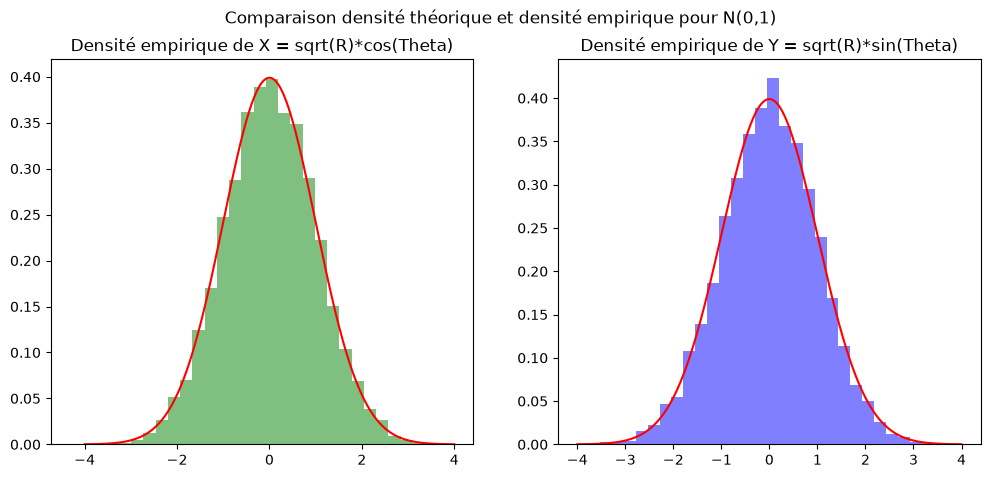

In [30]:
# comparaison densité théorique et densité empirique

from scipy.stats import norm

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
x = np.linspace(-4, 4, 1000)

ax[0].set_title("Densité empirique de X = sqrt(R)*cos(Theta)")
ax[0].hist(X, bins=30, density=True, alpha=0.5, color='g')
ax[0].plot(x, norm.pdf(x, loc=0, scale=1), color='red')

ax[1].set_title("Densité empirique de Y = sqrt(R)*sin(Theta)")
ax[1].hist(Y, bins=30, density=True, alpha=0.5, color='b')
ax[1].plot(x, norm.pdf(x, loc=0, scale=1), color='red')

plt.suptitle("Comparaison densité théorique et densité empirique pour N(0,1)")
plt.show()

-0.00013331021071109138


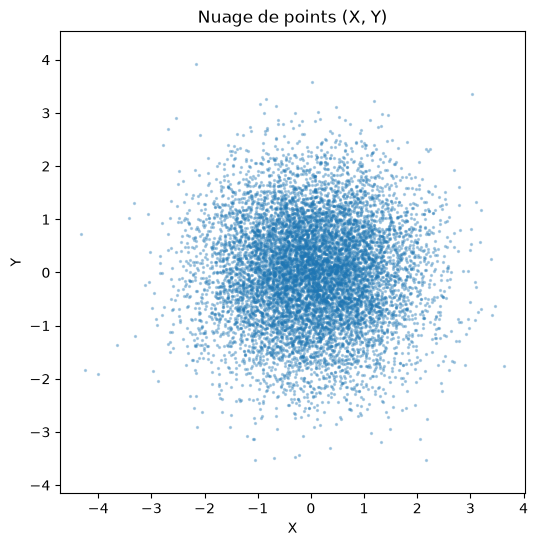

In [31]:
# vérification de l'indépendance de X et Y, empiriquement

print(np.corrcoef(X, Y)[0, 1])

plt.figure(figsize=(6, 6))
plt.scatter(X, Y, s=2, alpha=0.3)
plt.xlabel("X")
plt.ylabel("Y")
plt.axis('equal')
plt.title("Nuage de points (X, Y)")
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On observe un nuage de points isotrope, ainsi qu'un coeffcient de corrélation très proche de 0, ce qui montre/suggère que $X$ et $Y$ ne sont pas corrélées. Cela ne montre pas leur indépendance mais c'est du moins compatible avec le fait que $X$ et $Y$ soient indépendantes.
</div>

**Q3**. À partir de $N$ échantillons de loi $\mathcal{N}(0,1)$, comment obtenir un $N$ échantillons de loi $\mathcal{N}(\mu, \sigma^2)$ ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Pour $X \sim \mathcal{N}(0,1)$, alors :

$$ \mu + \sigma X \sim \mathcal{N}(\mu, \sigma^2)$$

On peut donc facilement construire, par translation et mise à l'échelle, des échantillons de $\mathcal{N}(\mu, \sigma^2)$ à partir de $\mathcal{N}(0, 1)$. On vérifie cela expérimentalement :

</div>

In [32]:
np.random.seed(0)

N = 10000
mu = 2
sigma = 0.5

# generation des samples de N(0,1) (cf précédemment)
U = np.random.uniform(low=0, high=1, size=N)
V = np.random.uniform(low=0, high=1, size=N)
R = -2*np.log(1-U) # suit exp(1/2)
Theta = 2*np.pi*V # suit U(0, 2pi)
X = np.sqrt(R) * np.cos(Theta)

Y = mu + sigma * X

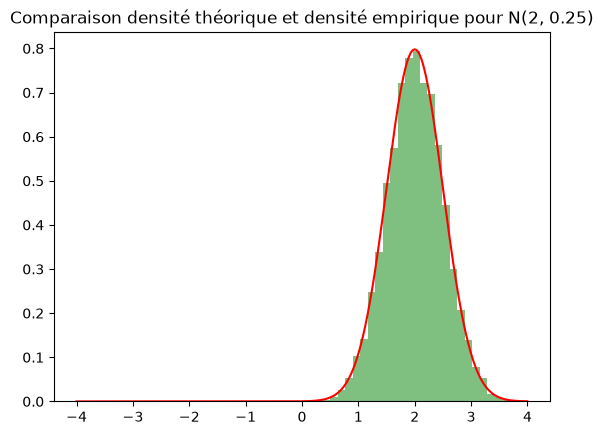

Moyenne empirique : 2.009139537745797
Variance empirique : 0.2494894652086837


In [33]:
# comparaison densité théorique et densité empirique

from scipy.stats import norm

plt.hist(Y, bins=30, density=True, alpha=0.5, color='g')
x = np.linspace(-4, 4, 1000)
plt.plot(x, norm.pdf(x, loc=mu, scale=sigma), color='red')

plt.title(f"Comparaison densité théorique et densité empirique pour N({mu}, {sigma**2})")
plt.show()

print(f"Moyenne empirique : {np.mean(Y)}")
print(f"Variance empirique : {np.var(Y)}")

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On obtient bien des échantillons de la loi attendue.

</div>

**Q4**. On s'intéresse maintenant à la simulation d'un **vecteur** gaussien en dimension $d$.

Expliquer pourquoi la méthode de Box-Müller permet de simuler des vecteurs de loi $\mathcal{N_d}(\mathbf{0}_d, I_d)$.

Soit $X \sim \mathcal{N_d}(\mathbf{0}_d, I_d)$, $\mathbf{m} \in \mathbb{R}^d$, et $\boldsymbol{\Sigma} \in \mathbb{R}^{d \times d}$ symétrique définie positive. On suppose qu'il existe $\mathbf{L} \in \mathbb{R}^{d \times d}$ tel que $\boldsymbol{\Sigma} = \mathbf{L} \mathbf{L}^{\top}$.

À l'aide des propriétés des vecteurs gaussiens, montrer que $Y = \mathbf{m} + \mathbf{L}X \sim \mathcal{N_d}(\mathbf{m}, \boldsymbol{\Sigma})$.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Un vecteur gaussien de loi $\mathcal{N_d}(\mathbf{0}_d, I_d)$ est un vecteur aléatoire composé de $d$ variables aléatoires indépendantes de loi $\mathcal{N}(0,1)$.

Ainsi, comme la méthode de Box-Müller nous permet d'échantillonner des variables aléatoires indépendantes de loi $\mathcal{N}(0,1)$, on peut simplement placer ces variables dans un vecteur et on aura échantillonné un vecteur aléatoire de loi $\mathcal{N_d}(\mathbf{0}_d, I_d)$.

On pose $Y = \mathbf{m} + \mathbf{L}X$. Alors, en tant que combinaison affine des composantes du vecteur gaussien $X$, $Y$ est bien un vecteur gaussien.

De plus, on calcule :

$$ \mathbb{E}[Y] = \mathbb{E}[\mathbf{m} + \mathbf{L}X] = \mathbb{E}[\mathbf{m}] + \mathbf{L} \mathbb{E}[X] = \mathbf{m}$$

et la matrice de covariance de $Y$ est donnée par :

$$ D_Y = \mathbf{L} D_X \mathbf{L}^T =  \mathbf{L}\mathbf{L}^T = \boldsymbol{\Sigma} $$

d'où $Y \sim \mathcal{N_d}(\mathbf{m}, \boldsymbol{\Sigma})$.

</div>

**Q5**. On peut montrer qu'une telle matrice $\mathbf{L}$ existe toujours. C'est la **décomposition de Cholesky** ($\mathbf{L}$ est triangulaire inférieure), qui est fondamentale en statistique et *machine learning*. Elle tire son nom d'André-Louis Cholesky, ingénieur polytechnicien, mort pendant la première guerre mondiale (résultat publié de manière posthume en 1924). À noter que la complexité associée à cette décomposition est $\mathcal{O}(d^3)$ !

À partir de $N$ échantillons de loi $\mathcal{N_d}(\mathbf{0}_d, I_d)$, générer $N$ échantillons de loi $\mathcal{N_d}(\mathbf{m}, \boldsymbol{\Sigma})$. Prendre $d=2$ et utiliser `np.linalg.cholesky`.

In [34]:
np.random.seed(0)

N = 10000

m = np.array([2, 3])
C = np.array([[1, 0.5], [0.5, 1]]) # symétrique définie positive
L = np.linalg.cholesky(C) # L @ L.T = C

U = np.random.uniform(low=0, high=1, size=N)
V = np.random.uniform(low=0, high=1, size=N)

R = -2*np.log(1-U)
Theta = 2*np.pi*V

X_1 = np.sqrt(R) * np.cos(Theta) # normale centrée réduite
X_2 = np.sqrt(R) * np.sin(Theta) # normale centrée réduite
X = np.vstack((X_1, X_2)).T # (N, 2), N echantillons de N_2(0_2, I_2)

# à partir de là, on veut générer des échantillons de N_2(m, C):
Y = m + (L @ X.T).T
# ré-écriture vectorisée de la formule Y = m + LX qui est valable pour X un vecteur colonne. 
# ici X est de taille (N,2) donc L @ X.T -> (2,2) @ (2,N) = (2,N) et on transpose pour obtenir (N,2)
# puis addition par m via broadcasting

moyenne théorique :
 [2 3]
moyenne empirique :
 [2.01827908 3.01226486]
covariance théorie :
 [[1.  0.5]
 [0.5 1. ]]
covariance empirique :
 [[0.99805767 0.49891446]
 [0.49891446 0.98684752]]


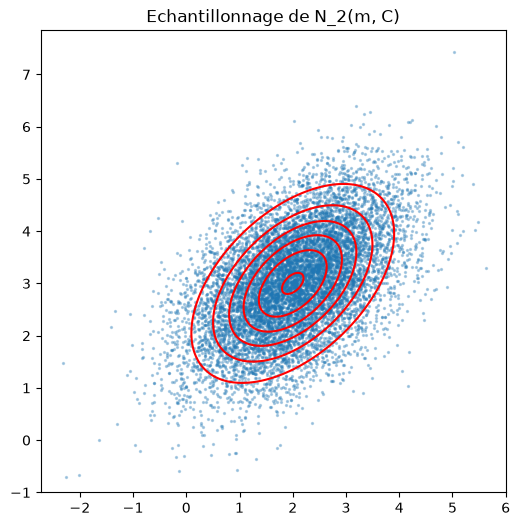

In [35]:
# vérifications :

# on vérifie ici la moyenne et la covariance
print("moyenne théorique :\n", m)
print("moyenne empirique :\n", Y.mean(axis=0))

print("covariance théorie :\n", C)
print("covariance empirique :\n", np.cov(Y.T))

# 2) nuage + courbes de niveau de la densité théorique N_2(m, C)
from scipy.stats import multivariate_normal
x1, x2 = np.meshgrid(np.linspace(-2, 6, 200), np.linspace(-1, 7, 200))
densite = multivariate_normal(mean=m, cov=C).pdf(np.dstack((x1, x2)))
# ici on reprend le code du tp1 de intro à lestimation statistiques pour afficher la densite d'une gaussienne multivariée

plt.figure(figsize=(6, 6))

plt.scatter(Y[:, 0], Y[:, 1], s=2, alpha=0.3) # échantillons
plt.contour(x1, x2, densite, levels=6, colors='red')
plt.title("Echantillonnage de N_2(m, C)")

plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Les vérifications nous permettent de confirmer que les échantillons suivent bien $\mathcal{N_d}(\mathbf{m}, \boldsymbol{\Sigma})$.

</div>

### Exercice 4 - Acceptation-Rejet (*Rejection sampling*)

**Q1**. On considère la loi Bêta, dont la densité sur $[0,1]$ est
$$f(x;\alpha, \beta) = \frac{\Gamma(\alpha + \beta)}{\Gamma(\alpha) \Gamma(\beta)} x^{\alpha-1} (1-x)^{\beta-1} \quad \alpha > 0, \quad \beta > 0.$$

On souhaite obtenir des échantillons de la loi Bêta dans le cas suivant : $\alpha = 2, \beta = 2$.
* Expliquer pourquoi il est difficile de mettre en place la méthode de la transformée inverse.
* Quelle loi très simple peut-on utiliser comme loi instrumentale ?
* Implémenter alors un algorithme acceptation-rejet pour obtenir $N = 10000$ échantillons.
* Comparer la proportion empirique d'échantillons acceptés avec sa valeur théorique.
* Quelle difficulté rencontre-t-on pour le cas $\alpha = \beta = 0.5$ ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Utiliser la méthode de la transformée inverse requiert ici de calculer la fonction de répartition F, puis de calculer sa réciproque (ce sont les limites dont nous avions parlé à la fin de l'exercice 2).

Pour le calcul de $F$, qui vaudrait avec $\alpha=\beta=2$ :

$$ \frac{\Gamma(\alpha+\beta)}{\Gamma(\alpha)\Gamma(\beta)} = \frac{\Gamma(4)}{\Gamma(2)\,\Gamma(2)} = \frac{3!}{1! \cdot 1!} = 6$$

d'où :

$$ f(x) = \big(6x - 6x^2 \big) 1_{[0,1]}(x)$$

et donc:

$$ F(x) = 3x^2 - 2x^3$$

sur $[0,1]$ (et 0 sur $\R_{-}$ et 1 sur $[1, + \infty [$)


Calculer la réciproque revient ainsi à résoudre une équation de degré 3.

On se tourne alors vers la méthode de rejection sampling, étant donné la forme de la densité sur $[0,1]$, on choisit la loi uniforme sur $[0,1]$ comme loi instrumentale.
</div>

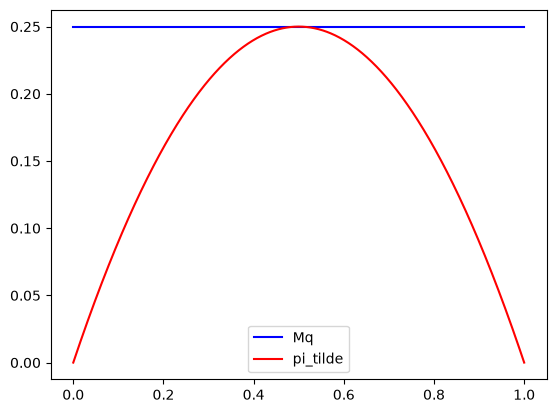

In [36]:
a, b = 2, 2

# version non normalisée de notre distribution pi (pi_tilde dans le cours)
def pi_tilde(x, a, b):
    return x**(a-1) * (1-x)**(b-1)

# son max est 0.25, on va donc l'envelopper par la loi uniforme sur [0, 1], qui est constante égale à 1
# et on peut prendre le M minimal de 0.25

# loi q  dans le cours, ici loi uniforme sur [0, 1]
def q(x):
    return np.ones_like(x)
M = 0.25

x = np.linspace(0, 1, 1000)
plt.plot(x, M * q(x), color='blue', label="Mq") # affichage de Mq
plt.plot(x, pi_tilde(x, a, b), color='red', label="pi_tilde") # affichage de pi_tilde
plt.legend()

# on a bien l'enveloppe Mq >= pi_tilde sur [0, 1]
# on peut alors faire le rejection sampling

In [37]:
np.random.seed(0)

N = 10000

accepted = []
total = 0

# algo de rejection sampling, on reprend le pseudocode du cours
while len(accepted) < N:
    Theta_0 = np.random.uniform(low=0, high=1, size=1)
    U = np.random.uniform(low=0, high=M*q(Theta_0), size=1)

    if U <= pi_tilde(Theta_0, a, b):
        accepted.append(Theta_0[0])
    total += 1

accept = np.array(accepted)
print(f"Taux d'acceptation: {N/total:.2f}")

Taux d'acceptation: 0.66


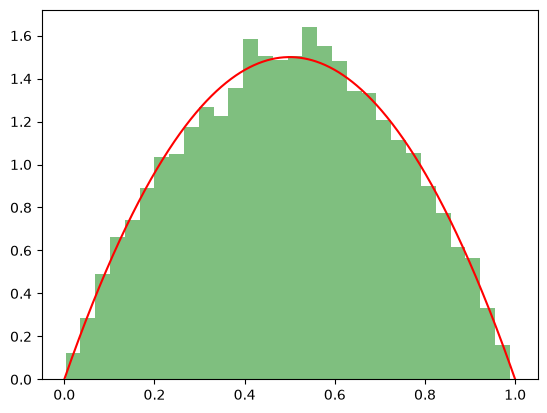

In [38]:
# comparaison densité théorique et densité empirique

from scipy.stats import beta

plt.hist(accept, bins=30, density=True, alpha=0.5, color='g')
plt.plot(np.linspace(0, 1, 1000), beta.pdf(np.linspace(0, 1, 1000), a, b), color='red')
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Tout d'abord, la densité expérimentale obtenue suit bien la densité théorique de la loi beta (2,2). La méthode fonctionne donc bien ici.

On obtient un taux d'acceptation expérimental de $0.66$.
En théorie, ce taux d'acceptation vaut le rapport entre l'aire sous la courbe de la densité de Beta(2,2) et l'aire sous la courbe de $Mq$.
La première aire vaut $\int_{[0,1]} x(1-x) dx = \frac{1}{6}$ et la seconde vaut $M=\frac{1}{4}$. Ainsi, le taux d'acceptation vaut $\frac{\frac{1}{6}}{\frac{1}{4}} = \frac{2}{3}$. On retrouve bien le taux expérimental.

On regarde maintenant le cas a=b=0.5.
En visualisant $\tilde{\pi}$ pour ce cas, on remarque qu'elle tend vers $+\infty$ en 0 et en 1. La méthode de rejection sampling ne peut donc s'appliquer puisqu'on ne peut pas majorer $\tilde{\pi}$.
</div>

/var/folders/4v/j98j235s7b30br93bwvc5ycm0000gn/T/ipykernel_51428/2819451700.py:5: RuntimeWarning: divide by zero encountered in power
  return x**(a-1) * (1-x)**(b-1)


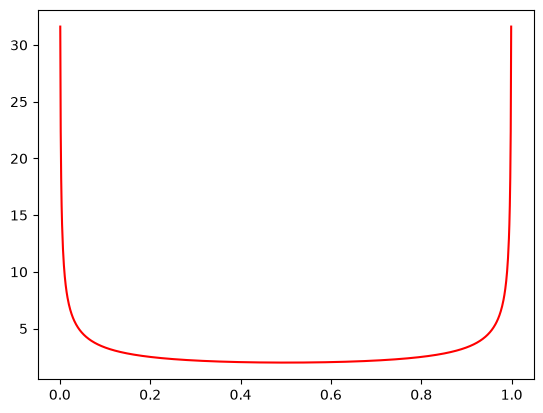

In [39]:
plt.plot(np.linspace(0, 1, 1000), pi_tilde(np.linspace(0, 1, 1000), 0.5, 0.5), color='red')

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On essaie quand même d'appliquer la technique, en "coupant" $\tilde{\pi}$ sur les bords, c'est-à-dire en considérant que $\tilde{\pi}$ est constante très proche de 0 et de 1.
On va donc utiliser la même loi majorante $q$ uniforme, c'est seulement le $M$ qu'on va adapter:

</div>

In [40]:
np.random.seed(0)

# même code que précédemment

N = 10000
a, b = 0.5, 0.5

accepted = []
total = 0

# on considère que pi_tilde est constante proche de 0 et 1
borne_basse = 0.001
borne_haute = 0.999
M = max(pi_tilde(borne_basse, a, b), pi_tilde(borne_haute, a, b))
# et on adapte ainsi M (donc Mq va coller pi_tilde proche de 0 et proche de 1, et sera toujours une enveloppe sur le reste)

# le reste ne change pas
while len(accepted) < N:
    Theta_0 = np.random.uniform(low=borne_basse, high=borne_haute, size=1)
    U = np.random.uniform(low=0, high=M*q(Theta_0), size=1)

    if U <= pi_tilde(Theta_0, a, b):
        accepted.append(Theta_0[0])
    total += 1

accept = np.array(accepted)
print(f"Taux d'acceptation: {N/total:.2f}")

Taux d'acceptation: 0.10


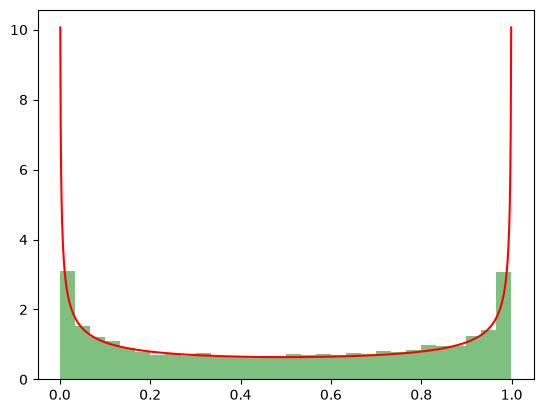

In [41]:
from scipy.stats import beta

plt.hist(accept, bins=30, density=True, alpha=0.5, color='g')
plt.plot(np.linspace(0, 1, 1000), beta.pdf(np.linspace(0, 1, 1000), a, b), color='red')
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On remarque que la méthode fonctionne globalement bien, mais, comme on pouvait s'en douter, considérer que Beta(0.5, 0.5) est constante proche de 0 et de 1 fait qu'on sous estime sa masse proche de ces 2 points et donc la distribution empirique obtenue n'est pas fidèle en 0 ni 1.

</div>

**Q2**. On souhaite maintenant obtenir des échantillons d'une loi gaussienne tronquée, i.e., une loi normale restreinte à un certain intervalle (en 1D), ou un certain pavé de l'espace (pour le cas multivarié).

On considère le cas d'une gaussienne multivariée $\mathcal{N}_d(0, I_d)$ que l'on tronque sur le pavé $[-1,2]^d$. On prendra comme loi instrumentale la loi $\mathcal{N}(0, I_d)$ (i.e., non tronquée)

* Justifier ce choix de loi instrumentale.
* Pour le cas univarié ($d=1$), calculer numériquement la probabilité d'acceptation de l'algorithme acceptation-rejet. On pourra utiliser `scipy.stats.cdf`.
* Que devient cette probabilité pour $d=10$ ? $d=100$ ? Conclure quant à la faiblesse fondamentale de l'algorithme acceptation-rejet.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Prendre la loi instrumentale $\mathcal{N}(0, I_d)$ pour faire du rejection sampling pour sampler $\mathcal{N}_d(0, I_d)$ tronquée est justifié car la densité de la loi instrumentale $q$ enveloppe bien celle de la loi tronquée $\tilde{\pi}$ non normalisée $\tilde{\pi}(\theta) = q(\theta)\mathbb{1}_{[-1,2]^d}(\theta)$, c'est-à-dire qu'en prenant $M=1$, on a bien $\forall \theta \in [-1,2]^d \; \tilde{\pi}(\theta) \leq Mq(\theta)$.

Pour calculer la probabilité d'acceptation, il s'agit de calculer la proportion des échantillons de $\mathcal{N}(0,1)$ qui vont tomber dans l'intervalle $[-1, 2]$. En effet, tous les échantillons qui tombent hors de cet intervalle vont être rejetés ($u \leq 0$ est de probabilité nulle), et tous les échantillons qui tombent dans cet intervalle sont acceptés (car $M=1$ et donc $M q(\theta_0) = \tilde{\pi}(\theta_0)$).
On calcule donc cette aire grâce à la fonction de répartition de la loi normale centrée réduite.

Dans le cas multivarié où les composantes sont indépendantes, on peut appliquer le même raisonnement qu'en univarié de façon indépendante. Ainsi, pour qu'un échantillon soit accepté, il faut que toutes les composantes satisfassent le test d'acceptation de rejection sampling, donc $p^d$ où $p$ est la probabilité calculée dans le cas univarié.
</div>

In [42]:
# proba d'acceptation, cas d=1

from scipy.stats import norm

proba_accept = 1 - norm.cdf(-1) - (1 - norm.cdf(2))
# aire qui correspond à la zone d'acceptation, ie aire sous la courbe entre -1 et 2
# = aire totale (1) - F(-1) - (1 - F(2))

print(f"Proba d'acceptation: {proba_accept:.2f}")

# cas d>1
d = 10
print(f"Proba d'acceptation pour d={d}: {proba_accept**d:.2f}")
d = 100
print(f"Proba d'acceptation pour d={d}: {proba_accept**d:.10f}")

Proba d'acceptation: 0.82
Proba d'acceptation pour d=10: 0.14
Proba d'acceptation pour d=100: 0.0000000020


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Le taux d'acceptation pour le cas univarié est satisfaisant, mais en haute dimension, il décroît de manière exponentielle et tombe très proche de zéro à partir d'environ 20-25 dimensions. Pour $d=100$, la probabilité d'acceptation est tellement petite qu'utiliser rejection sampling devient impossible en pratique.
</div>

### Exercice 5 - Estimation de $\pi$ par Monte Carlo

On rappelle que $\pi$ est égal à la surface d'un cercle de rayon 1, i.e.
$$ \pi = \int_{-1}^1 \int_{-1}^1 \mathbb{1}_{x^2 + y^2 \leq 1}(x,y) dx dy.$$

Ce qui peut se réécrire comme
$$ \pi = 4 \int_{-1}^1 \int_{-1}^1 \mathbb{1}_{x^2 + y^2 \leq 1}(x,y) p(x) p(y) dx dy.$$
Où $p(x)$ et $p(y)$ sont les densités de la loi uniforme sur $[-1,1]$.

* En déduire l'esimtateur de Monte Carlo de $\pi$.
* Générer $N_s = 10000$ échantillons, puis représenter l'évolution de la valeur de l'estimation par Monte Carlo de $\pi$ en ne gardant que les $N$ premiers. Quel résultat fondamental est-on en train d'illustrer ?
* Faire 1000 simulations de l'estimation par Monte Carlo de $\pi$ avec $N_s = 10000$ échantillons, et vérifier le résultat de convergence en loi de l'estimateur de Monte Carlo donné par le TCL.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Déduction de l'estimateur de Monte Carlo de $\pi$:

On reconnait :

$$\pi = 4 \int_{-1}^1 \int_{-1}^1 \mathbb{1}_{x^2 + y^2 \leq 1}(x,y) p(x) p(y) dx dy$$

comme :

$$\pi = 4 \times \mathbb{E}_{X \sim U[-1, 1], Y \sim U[-1, 1]}[1_{X^2+Y^2\leq 1}] $$

donc, à partir d'échantillons de variables aléatoires uniformes sur [-1, 1], on va calculer la moyenne empirique de $4 \times 1_{X^2+Y^2\leq 1}$, c'est-à-dire, compter le nombre d'échantillons qui satisfont $X^2+Y^2\leq 1$, diviser par $N_s$, puis multiplier par 4.

</div>

In [43]:
# estimation de pi par méthode de monte carlo

np.random.seed(42)

N_s = 10000

X = np.random.uniform(low=-1, high=1, size=N_s)
Y = np.random.uniform(low=-1, high=1, size=N_s)

# np.where = indices des éléments qui satisfont la condition
# donc ici on récupère la shape de ce tableau pour compter le nombre de points dans le cercle unité
pi_estimate = 4 * np.where(X**2 + Y**2 <= 1)[0].shape[0] / N_s

print(f"Estimation de pi: {pi_estimate:.4f}")

Estimation de pi: 3.1348


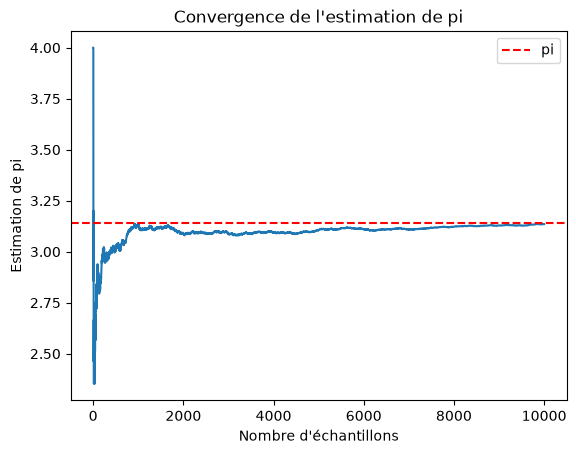

In [44]:
# evolution de l'estimation de pi en fonction du nombre d'échantillons
pi_estimates = []
for n in range(1, N_s + 1):
    pi_estimate = 4 * np.where(X[:n]**2 + Y[:n]**2 <= 1)[0].shape[0] / n
    pi_estimates.append(pi_estimate)

plt.plot(pi_estimates)
plt.axhline(y=np.pi, color='r', linestyle='--', label='pi')
plt.xlabel("Nombre d'échantillons")
plt.ylabel("Estimation de pi")
plt.title("Convergence de l'estimation de pi")
plt.legend()
plt.show()

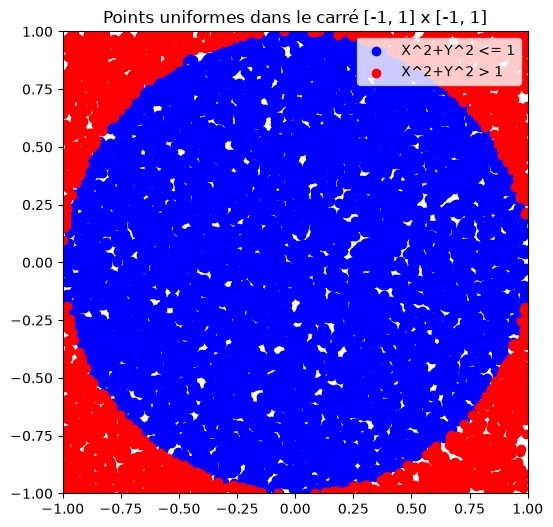

In [45]:
# visualisation du tirage de tous les points dans [-1,1]^2, puis comptage
# on peut aussi voir notre calcul comme un calcul approché d'une proportion d'aire
plt.figure(figsize=(6, 6))
plt.scatter(X[X**2 + Y**2 <= 1], Y[X**2 + Y**2 <= 1], color='blue', label='X^2+Y^2 <= 1')
plt.scatter(X[X**2 + Y**2 > 1], Y[X**2 + Y**2 > 1], color='red', label='X^2+Y^2 > 1')
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.title("Points uniformes dans le carré [-1, 1] x [-1, 1]")
plt.legend()

Text(0.5, 1.0, 'Distribution des estimations de pi sur 1000 tirages')

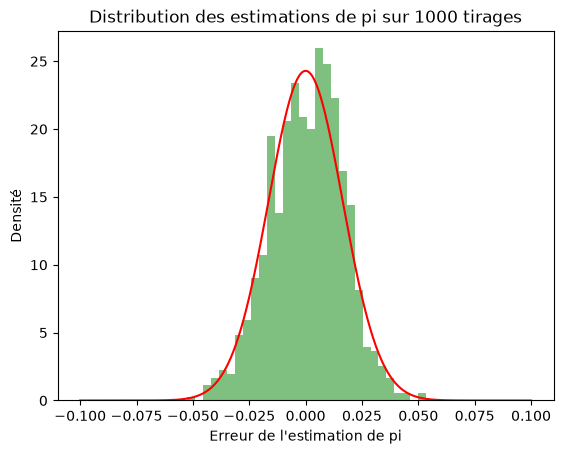

In [46]:
# vérification de la convergence en loi de l'estimateur

np.random.seed(42)

N_tot = 1000
N_s = 10000

pi_estimates = []

for _ in range(N_tot):
    # estimation de pi, même code qu'au dessus
    X = np.random.uniform(low=-1, high=1, size=N_s)
    Y = np.random.uniform(low=-1, high=1, size=N_s)
    pi_estimate = 4 * np.where(X**2 + Y**2 <= 1)[0].shape[0] / N_s
    pi_estimates.append(pi_estimate)
pi_estimates = np.array(pi_estimates)

plt.hist(pi_estimates-np.pi, bins=30, density=True, alpha=0.5, color='g')
x = np.linspace(-0.1, 0.1, 1000)
plt.plot(x, norm.pdf(x, loc=0, scale=np.sqrt(np.pi*(4-np.pi)/N_s)), color='red')
plt.xlabel("Erreur de l'estimation de pi")
plt.ylabel("Densité")
plt.title("Distribution des estimations de pi sur 1000 tirages")

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

L'estimation de $\pi$ converge bien vers la valeur de $\pi$ à mesure que le nombre d'échantillons augmente : l'estimateur est sans biais. Cette convergence de la moyenne empirique vers l'espérance est assurée par la loi des grands nombres, qui assure que l'estimateur de l'intégrale par la moyenne empirique est fortement convergent.

Pour observer la convergence en loi de notre estimateur (et ainsi vérifier le TCL), il faut répéter plusieurs fois l'estimation et observer la distribution des "erreurs", c'est-à-dire la distribution des :

$$ \hat{I}_{MC} - \pi $$

D'après le TCL, on a la convergence en loi de :

$$\sqrt{N_s} \Big( \hat{I}_{MC} - \pi \Big) \rightarrow \mathcal{N}(0, \text{Var}(4 \times 1_{X^2+Y^2\leq 1}))$$

où $1_{X^2+Y^2\leq 1}$ suit une loi de Bernoulli $B(\frac{\pi}{4})$, de variance $\frac{\pi}{4}(1-\frac{\pi}{4}) = \frac{\pi(4 - \pi)}{16}$. Ainsi : 

$$\sqrt{N_s} \Big( \hat{I}_{MC} - \pi \Big) \rightarrow \mathcal{N}(0, \pi(4-\pi))$$

donc l'erreur $\hat{I}_{MC} - \pi$ doit suivre une loi normale $\mathcal{N}(0, \frac{\pi(4-\pi)}{N_s})$.
C'est bien ce qu'on retrouve expérimentalement.

La vitesse de convergence de l'estimateur de $\pi$ se fait donc en $\sqrt{N_s}$ où $N_s$ est le nombre d'échantillons.

</div>

### Exercice 6 - Échantillonnage d'importance (*Importance sampling*)

On cherche à estimer $\mathbb{P}(X > 3)$ avec $X \sim \mathcal{N}(0,1)$.

* Ré-écrire cette probabilité comme une intégrale et en déduire l'estimateur de Monte Carlo "standard".
* Simuler $1000$ fois $N_s = 10000$ échantillons, et calculer la moyenne et la variance empiriques de l'estimateur de Monte Carlo standard.
* On souhaite maintenant implémenter un schéma d'échantillonnage d'importance en utilisant comme loi instrumentale $\mathcal{N}(4,1)$. Donner l'estimateur de Monte Carlo associé.
* De même, simuler $1000$ fois $N_s = 10000$ échantillons, et calculer la moyenne et la variance empiriques de de deuxième estimateur.
* Quantifier la réduction de variance. Commenter.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On écrit :

$$\mathbb{P}(X > 3) = \int_3^{+\infty} f(x)dx$$

où $f$ est la densité de la loi normale. On re-écrit alors :

$$\mathbb{P}(X > 3) = \int_\R 1_{]3, +\infty[}(x)f(x)dx$$

d'où :

$$\mathbb{P}(X > 3) = \mathbb{E}[1_{X > 3}]$$

On en déduit l'estimateur par Monte Carlo de $\mathbb{P}(X > 3)$ :

$$\hat{p}_{MC} = \frac{1}{N_s} \sum_{i=1}^{N_s} 1_{X_i > 3}$$

avec $X_i \overset{iid}{\sim} \mathcal{N}(0,1)$

</div>

In [47]:
# estimation de P(X>3) par méthode de monte carlo
from scipy.stats import norm

np.random.seed(42)

N_tot = 1000
N_s = 10000

estimates = []

for _ in range(N_tot):
    # la formulation est similaire à celle de l'exercice 5, on reprend le même code
    X = np.random.normal(loc=0, scale=1, size=N_s)
    estimate = np.where(X>3)[0].shape[0] / N_s
    estimates.append(estimate)

estimates = np.array(estimates)
estimates_MC = estimates.copy() # on garde les estimations MC pour la comparaison finale

print(f"Valeur théorique de P(X>3): {1-norm.cdf(3):.8f}")
print(f"Estimation de P(X>3): {np.mean(estimates):.8f}")
print(f"Variance de l'estimateur: {np.var(estimates):.3e}")

Valeur théorique de P(X>3): 0.00134990
Estimation de P(X>3): 0.00134640
Variance de l'estimateur: 1.319e-07


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

A partir de :

$$\mathbb{P}(X > 3) = \int_\R 1_{]3, +\infty[}(x)f(x)dx$$

on écrit :

$$\int_\R 1_{[3, +\infty[}(x)f(x)dx = \int_\R 1_{]3, +\infty[}(x)\frac{f(x)}{\hat{f}(x)} \hat{f}(x)dx$$

et donc :

$$\mathbb{P}(X > 3) = \mathbb{E}_{X \sim \mathcal{N}(4, 1)}[1_{X > 3} \frac{f(X)}{\hat{f}(X)}]$$

où $\hat{f}$ est la densité de la loi normale réduite centrée en 4. On échantillonnage alors cette espérance par la méthode de Monte Carlo, ce qui donne l'estimateur suivant :

$$\hat{p}_{IS} = \frac{1}{N_s} \sum_{i=1}^{N_s} 1_{X_i > 3} \, \frac{f(X_i)}{\hat{f}(X_i)}$$

avec $X_i \overset{iid}{\sim} \mathcal{N}(4,1)$

</div>

In [48]:
# estimation de P(X>3) par importance sampling+MC

np.random.seed(42)

N_tot = 1000
N_s = 10000

estimates = []

for _ in range(N_tot):
    X = np.random.normal(loc=4, scale=1, size=N_s)
    # on fait la moyenne, sur les N_s echantillons, de 1_{X>3}*f(X)/q(X)
    w = norm.pdf(X) / norm.pdf(X, loc=4, scale=1)
    estimate = ((X>3) * w).mean()
    estimates.append(estimate)
estimates_IS = np.array(estimates) # idem pour les estimations IS

print(f"Valeur théorique de P(X>3): {1-norm.cdf(3):.8f}")
print(f"Estimation de P(X>3): {np.mean(estimates):.8f}")
print(f"Variance de l'estimateur: {np.var(estimates):.3e}")

Valeur théorique de P(X>3): 0.00134990
Estimation de P(X>3): 0.00135020
Variance de l'estimateur: 8.993e-10


In [49]:
1.319e-07/8.993e-10

146.6696319359502

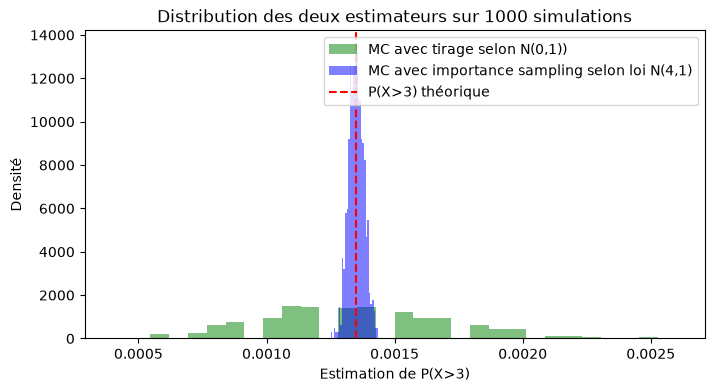

In [50]:
# comparaison des deux estimateurs

p_th = 1 - norm.cdf(3) # valeur théorique

plt.figure(figsize=(8, 4))

plt.hist(estimates_MC, bins=30, density=True, alpha=0.5, color='g', label="MC avec tirage selon N(0,1))")
plt.hist(estimates_IS, bins=30, density=True, alpha=0.5, color='b', label="MC avec importance sampling selon loi N(4,1)")
plt.axvline(p_th, color='r', linestyle='--', label="P(X>3) théorique")

plt.xlabel("Estimation de P(X>3)")
plt.ylabel("Densité")
plt.title("Distribution des deux estimateurs sur 1000 simulations")
plt.legend()
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On observe une réduction de variance par 150 environ entre l'échantillonnage selon $\mathcal{N}(0,1)$ et l'importance sampling selon $\mathcal{N}(4,1)$.

Cette réduction s'explique par le fait que l'évènement $\{X > 3\}$ est très rare en échantillonnant $X \sim \mathcal{N}(0,1)$ (proba de 0.13%). Ainsi, sur les 10000 échantillons générés, l'estimation se base sur seulement une dizaine de ces échantillons, donc elle a une haute variance.
Au contraire, en échantillonnant $X \sim \mathcal{N}(4,1)$, l'évènement $\{X > 3\}$ est beaucoup plus probable (84%) donc l'estimation se base sur un beaucoup plus grand nombre d'échantillons et donc a moins de variance.

</div>